Problem and target. Royal Road's recommendation team has thousands of new serials a quarter and few recommendation slots. At chapter 3 we know the first three chapters, the tags, and whether the author has written before. The question: will the serial end up in the top 10% of followers among serials that started in the same quarter?

Reads saved results only. Sources: `eda/01_eda.ipynb` (raw data facts), `embedding/01_prepare.py` (sample and target).

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
load = lambda rel: json.loads((ROOT / rel).read_text())
show = lambda rel, width=720: display(Image(filename=str(ROOT / rel), width=width))
pd.set_option("display.precision", 3)

Followers are one snapshot (about 2025-06-16), with no growth curve, and most serials are barely read.

In [2]:
s = load("reports/eda/summary.json")
print(f"{s['n_rows']:,} chapters, {s['n_fictions']:,} serials, {s['n_authors']:,} authors, {s['date_min']} to {s['date_max']}")
print(f"Serials with zero followers: {s['share_zero_followers']:.1%}")
pd.Series(s["followers_q"], name="followers").rename(lambda q: f"P{float(q) * 100:g}").to_frame().T

1,613,875 chapters, 86,959 serials, 56,458 authors, 2013-03-30 to 2025-06-16
Serials with zero followers: 26.8%


,P50,P75,P90,P95,P99,P99.9
followers,3.0,16.0,116.0,406.0,2386.26,9387.714


Older serials have had more time to collect followers, so ranking against all serials would teach the model that older is better.

In [3]:
age = pd.DataFrame(s["age_table"]).T
age.index = ["< 3 months", "3–12 months", "1–3 years", "> 3 years"]
age.columns = ["serials", "top-10% rate (all serials pooled)", "median followers"]
age

,serials,top-10% rate (all serials pooled),median followers
< 3 months,6387.0,0.027,2.0
3–12 months,11325.0,0.069,3.0
1–3 years,16184.0,0.110,6.0
> 3 years,24101.0,0.128,15.0


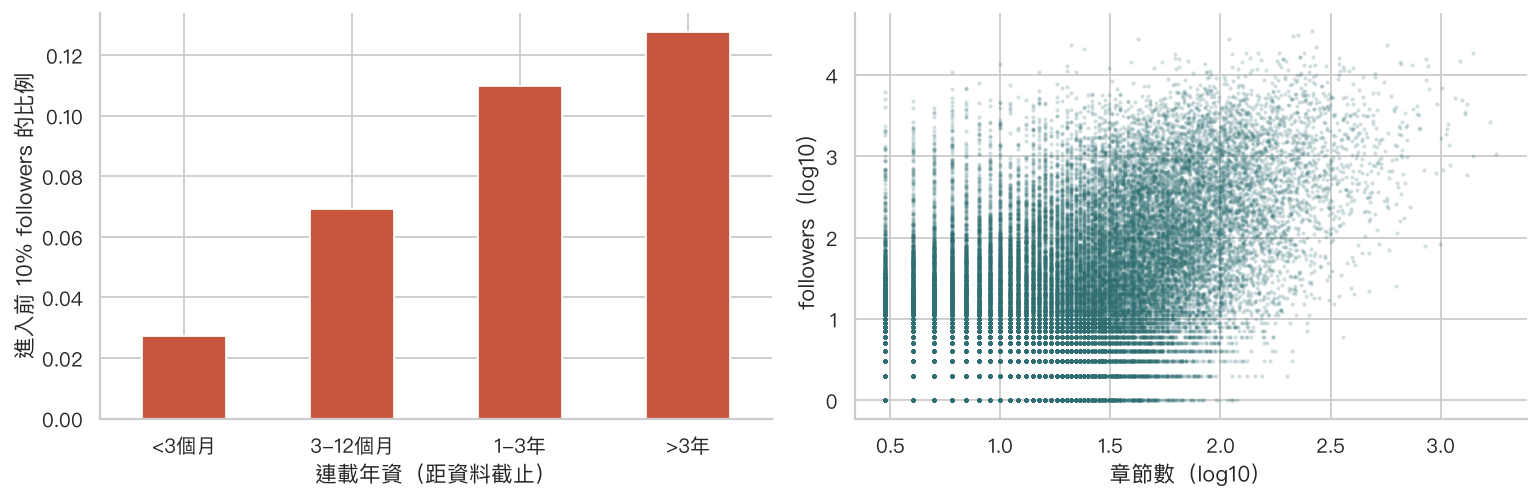

In [4]:
show("reports/eda/figs/age_leakage.png")

Target, for serial $i$ with followers $F_i$ that started in quarter $q_i$:

$$
Y_i=\begin{cases}1, & F_i \ge Q_{0.9}\big(\{F_j : q_j = q_i\}\big)\\ 0, & \text{otherwise}\end{cases}
$$

Sample: serials started in 2016–2024 with at least 3 chapters.

In [5]:
q = pd.DataFrame(load("reports/eda/quarters.json"))
q["year"] = q.q.str[:4].astype(int)
yearly = q[q.year.between(2016, 2024)].groupby("year").agg(new_serials=("n", "sum"), top10_threshold_median=("p90", "median"))
yearly

,new_serials,top10_threshold_median
year,,
2016,2205,355.50
2017,2503,316.25
2018,2877,340.40
2019,2913,347.00
2020,4036,345.30
2021,4771,294.75
2022,5700,283.15
2023,8075,325.15
2024,12165,213.65


The followers needed for the top 10% stay around 250–440 a quarter until late 2024, when they fall because those serials have had little time. So 2023 is the test year and 2024 only a secondary check.

In [6]:
split = pd.DataFrame(load("cover/out/cover_merge.json")["split_counts"]).set_index("split")[["n", "hit_rate_all"]]
split.index = ["train 2017–2021", "validation 2022", "test 2023", "recent 2024"]
split.columns = ["serials", "top-10% share"]
split

,serials,top-10% share
train 2017–2021,17100,0.101
validation 2022,5700,0.100
test 2023,8075,0.100
recent 2024,12165,0.100


Takeaways: the target is relative to the release quarter, which removes the "older serials have more followers" effect. 45,245 serials; 2016 is left out of training because 75% of its serials carry anti-piracy watermarks in the chapter text (notebook 3). Followers, tags and blurbs are one 2025 snapshot, so the backtest is not a strict replay of what was known at chapter 3.